Saving waterQuality1.csv to waterQuality1 (1).csv
Dropped 3 rows because target column had missing values.
Dataframe shape after cleaning: (7996, 21)
Target encoded with classes: ['0', '1']
X shape: (7996, 20) | y shape: (7996,)
Train: (5357, 20) | Test: (2639, 20)

Accuracy (All features): 89.81%

Best threshold: 0.0000
Number of selected features: 13
Accuracy with selected features: 89.88%

Final model accuracy: 89.88%


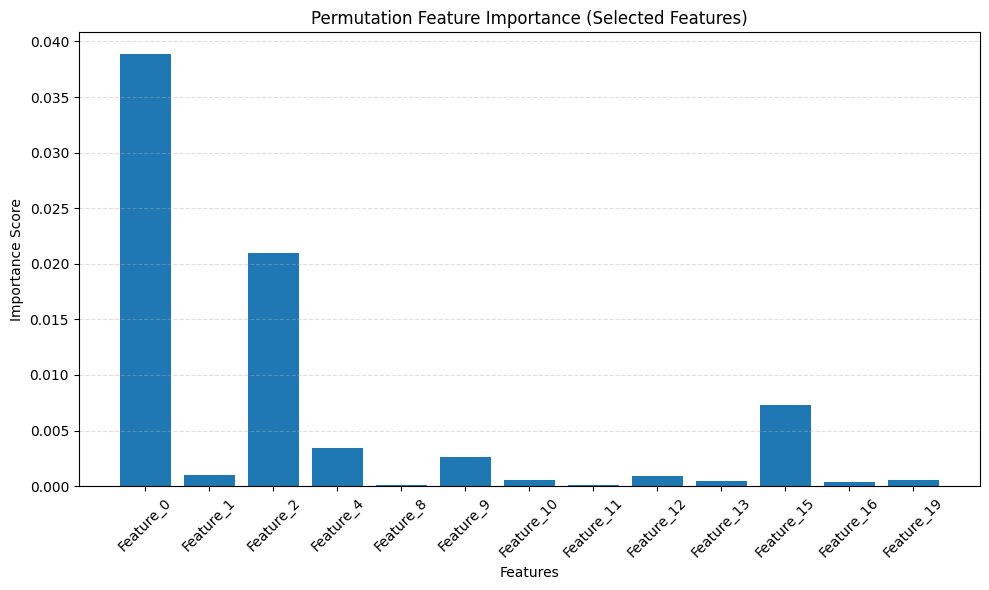

In [2]:
# -------------------------
# Permutation Feature Importance with automatic threshold
# -------------------------
from google.colab import files
uploaded = files.upload()

import numpy as np
import pandas as pd
from pandas import read_csv
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

# -------------------------
# Load + clean dataframe
# -------------------------
def load_and_clean_df(filename):
    df = read_csv(filename)
    df = df.replace(['#NUM!', '#DIV/0!', '#REF!', '#VALUE!', '#NULL!', '#N/A', ''], np.nan)
    target_col = df.columns[-1]
    before = df.shape[0]
    df = df.dropna(subset=[target_col])
    after = df.shape[0]
    if before != after:
        print(f"Dropped {before - after} rows because target column had missing values.")
    return df

# -------------------------
# Preprocess X and y
# -------------------------
def preprocess_df(df):
    X_df = df.iloc[:, :-1].copy()
    y_ser = df.iloc[:, -1].copy()
    if y_ser.dtype == object:
        y_ser = y_ser.astype(str)
        le_y = LabelEncoder()
        y = le_y.fit_transform(y_ser)
        print(f"Target encoded with classes: {list(le_y.classes_)}")
    else:
        y = pd.to_numeric(y_ser, errors='coerce').values
        if np.isnan(y).any():
            mask = ~np.isnan(y)
            X_df = X_df.loc[mask].reset_index(drop=True)
            y = y[mask]
            print("Dropped rows with NaN in target.")
    for col in X_df.columns:
        if X_df[col].dtype == object:
            conv = pd.to_numeric(X_df[col], errors='coerce')
            if conv.notna().sum() > 0 and conv.isna().sum() < len(conv):
                X_df[col] = conv
            else:
                X_df[col] = LabelEncoder().fit_transform(X_df[col].astype(str))
    X_arr = X_df.astype(float).values
    imputer = SimpleImputer(strategy="mean")
    X_imp = imputer.fit_transform(X_arr)
    return X_imp, np.asarray(y)

# -------------------------
# Plot feature importance
# -------------------------
def plot_feature_scores(scores, title, feature_names=None):
    plt.figure(figsize=(10,6))
    plt.bar(range(len(scores)), scores)
    plt.title(title)
    plt.xlabel("Feature Index" if feature_names is None else "Features")
    plt.ylabel("Importance Score")
    if feature_names is not None:
        plt.xticks(range(len(scores)), feature_names, rotation=45)
    else:
        plt.xticks(range(len(scores)))
    plt.grid(axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

# -------------------------
# MAIN
# -------------------------
df = load_and_clean_df(list(uploaded.keys())[0])
print("Dataframe shape after cleaning:", df.shape)

X, y = preprocess_df(df)
print("X shape:", X.shape, "| y shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=1)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# -------------------------
# Base Logistic Regression
# -------------------------
clf = LogisticRegression(solver='liblinear', max_iter=1000)
clf.fit(X_train, y_train)
acc_all = accuracy_score(y_test, clf.predict(X_test))
print(f"\nAccuracy (All features): {acc_all*100:.2f}%")

# -------------------------
# Permutation Feature Importance
# -------------------------
pfi = permutation_importance(clf, X_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)
feature_importances = pfi.importances_mean

# -------------------------
# Automatically find best threshold
# -------------------------
thresholds = np.linspace(0, max(feature_importances), 50)
best_acc = 0
best_threshold = 0
best_features_idx = np.arange(X.shape[1])

for t in thresholds:
    idx = np.where(feature_importances > t)[0]
    if len(idx) == 0:
        continue
    X_train_reduced = X_train[:, idx]
    X_test_reduced = X_test[:, idx]
    clf_tmp = LogisticRegression(solver='liblinear', max_iter=1000)
    clf_tmp.fit(X_train_reduced, y_train)
    acc = accuracy_score(y_test, clf_tmp.predict(X_test_reduced))
    if acc >= best_acc:  # maximize accuracy
        best_acc = acc
        best_threshold = t
        best_features_idx = idx

print(f"\nBest threshold: {best_threshold:.4f}")
print(f"Number of selected features: {len(best_features_idx)}")
print(f"Accuracy with selected features: {best_acc*100:.2f}%")

# -------------------------
# Retrain final model with selected features
# -------------------------
X_train_sel = X_train[:, best_features_idx]
X_test_sel = X_test[:, best_features_idx]

clf_final = LogisticRegression(solver='liblinear', max_iter=1000)
clf_final.fit(X_train_sel, y_train)
acc_final = accuracy_score(y_test, clf_final.predict(X_test_sel))
print(f"\nFinal model accuracy: {acc_final*100:.2f}%")

# -------------------------
# Plot final feature importances
# -------------------------
plot_feature_scores(
    feature_importances[best_features_idx],
    "Permutation Feature Importance (Selected Features)",
    feature_names=[f"Feature_{i}" for i in best_features_idx]
)
